In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

In [5]:
# ---------------------------------------------------------
# Paths
# ---------------------------------------------------------

PROJECT_DIR = Path("/Users/hyuna/OpenNeuro/ds007116")
DERIVED_DIR = PROJECT_DIR / "derived"

INPUT_FILE = DERIVED_DIR / "clustering_input_z.csv"

print(INPUT_FILE)
print("Exists:", INPUT_FILE.exists())

/Users/hyuna/OpenNeuro/ds007116/derived/clustering_input_z.csv
Exists: True


In [6]:
FEATURES = [
    "eswan_adhd_inattention_total",
    "eswan_adhd_hyperactivity_impulsivity_total",
    "bissc_total",
    "bas_total",
    "im_average",
    "em_average",
    "cnb_cptnl_total_sen",
    "cnb_cptnl_total_fp",
    "cnb_edisc_tot",
    "cnb_ddisc_tot",
    "cnb_rdisc_tot",
]

In [7]:
df = pd.read_csv(INPUT_FILE)

print("Shape:", df.shape)
display(df.head())

Shape: (92, 13)


,participant_id,session_id,eswan_adhd_inattention_total,eswan_adhd_hyperactivity_impulsivity_total,bissc_total,bas_total,im_average,em_average,cnb_cptnl_total_sen,cnb_cptnl_total_fp,cnb_edisc_tot,cnb_ddisc_tot,cnb_rdisc_tot
0,sub-138950,ses-1,1.254252,0.758607,-0.689221,0.020509,-0.294198,0.404862,0.383868,-0.338808,-0.159318,-0.170596,-0.713106
1,sub-19861,ses-1,-0.712643,-0.618167,-0.428281,-1.140630,-0.200218,-0.010535,0.726746,-1.069883,-0.831670,-0.917971,1.728038
2,sub-20125,ses-1,-0.494099,0.334984,-0.428281,0.746221,-0.764096,0.404862,0.155510,-0.272347,-0.966140,-0.170596,0.354895
3,sub-20139,ses-1,-0.057011,-0.512261,-0.167342,0.746221,-1.233995,-1.672126,0.155510,-0.272347,-0.966140,0.389935,-0.407963
4,sub-20141,ses-1,-1.040459,-0.512261,0.876417,0.020509,-1.046036,-1.118262,0.726746,-0.338808,0.513033,0.203091,0.812609


In [8]:
X = df[FEATURES].to_numpy()

print("GMM input shape:", X.shape)

assert X.shape == (92, 11)
assert np.isfinite(X).all()

GMM input shape: (92, 11)


In [9]:
pd.DataFrame(
    {
        "mean": df[FEATURES].mean(),
        "sd": df[FEATURES].std(ddof=0)
    }
).round(3)

,mean,sd
eswan_adhd_inattention_total,-0.0,1.0
eswan_adhd_hyperactivity_impulsivity_total,-0.0,1.0
bissc_total,0.0,1.0
bas_total,-0.0,1.0
im_average,-0.0,1.0
em_average,0.0,1.0
cnb_cptnl_total_sen,-0.0,1.0
cnb_cptnl_total_fp,-0.0,1.0
cnb_edisc_tot,0.0,1.0
cnb_ddisc_tot,0.0,1.0


In [10]:
model_results = []
fitted_models = {}

for k in range(2, 7):

    gmm = GaussianMixture(
        n_components=k,
        covariance_type="full",
        n_init=200,
        random_state=42,
        max_iter=1000
    )

    labels = gmm.fit_predict(X)

    fitted_models[k] = gmm

    cluster_sizes = (
        pd.Series(labels)
        .value_counts()
        .sort_index()
        .tolist()
    )

    if len(np.unique(labels)) > 1:
        sil = silhouette_score(X, labels)
    else:
        sil = np.nan

    model_results.append({
        "k": k,
        "BIC": gmm.bic(X),
        "AIC": gmm.aic(X),
        "silhouette": sil,
        "cluster_sizes": "/".join(map(str, cluster_sizes)),
        "converged": gmm.converged_,
        "n_iter": gmm.n_iter_
    })

model_results = pd.DataFrame(model_results)

display(model_results)

,k,BIC,AIC,silhouette,cluster_sizes,converged,n_iter
0,2,2772.253727,2381.376497,0.205466,8/84,True,2
1,3,2721.062843,2133.486105,0.244308,81/8/3,True,2
2,4,2753.401695,1969.125448,0.100613,7/27/53/5,True,19
3,5,2707.918528,1726.942771,0.111988,6/41/9/7/29,True,5
4,6,2659.775144,1482.099879,0.104152,5/40/5/10/6/26,True,16


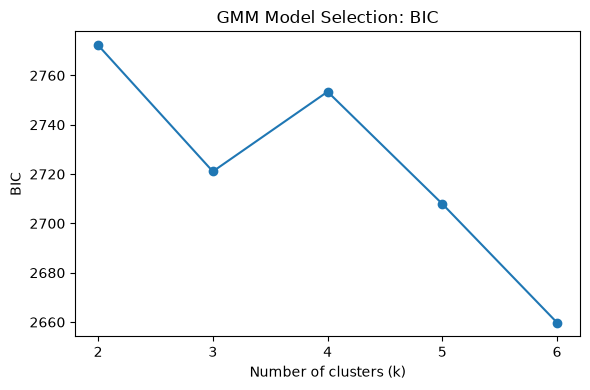

In [11]:
plt.figure(figsize=(6, 4))

plt.plot(
    model_results["k"],
    model_results["BIC"],
    marker="o"
)

plt.xlabel("Number of clusters (k)")
plt.ylabel("BIC")
plt.title("GMM Model Selection: BIC")
plt.xticks(model_results["k"])

plt.tight_layout()
plt.show()

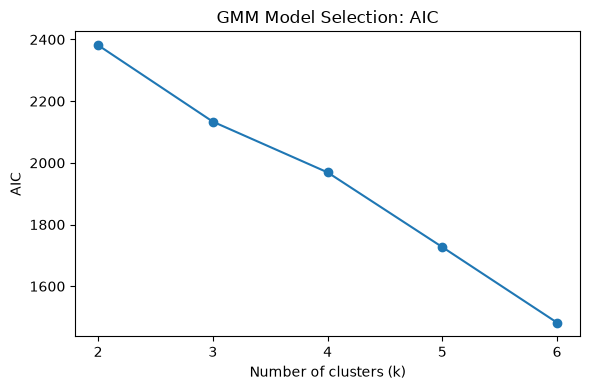

In [12]:
plt.figure(figsize=(6, 4))

plt.plot(
    model_results["k"],
    model_results["AIC"],
    marker="o"
)

plt.xlabel("Number of clusters (k)")
plt.ylabel("AIC")
plt.title("GMM Model Selection: AIC")
plt.xticks(model_results["k"])

plt.tight_layout()
plt.show()

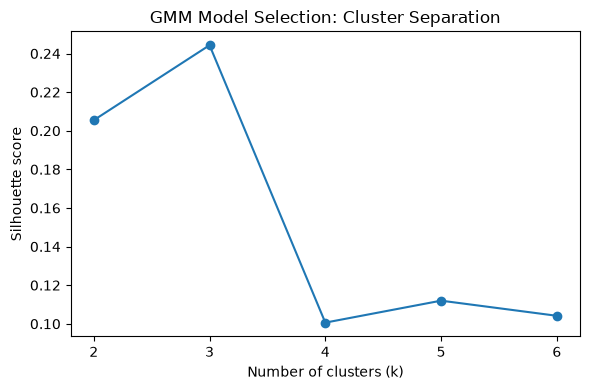

In [13]:
plt.figure(figsize=(6, 4))

plt.plot(
    model_results["k"],
    model_results["silhouette"],
    marker="o"
)

plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("GMM Model Selection: Cluster Separation")
plt.xticks(model_results["k"])

plt.tight_layout()
plt.show()

In [ ]:
## Comparison of five- and six-component solutions

Information criteria continued to improve from k=5 to k=6.
Therefore, model selection was not based solely on the minimum
BIC/AIC. The five- and six-component solutions were additionally
examined with respect to subgroup size, separation, parsimony,
and phenotype profiles.

In [14]:
X_profile = pd.DataFrame(
    X,
    columns=FEATURES
)

In [15]:
profiles = {}
assignments = {}

for k in [5, 6]:

    gmm = fitted_models[k]
    labels = gmm.predict(X)

    assignments[k] = labels

    temp = X_profile.copy()
    temp["cluster"] = labels

    profiles[k] = (
        temp
        .groupby("cluster")[FEATURES]
        .mean()
    )

    print(f"\n=== k={k} ===")

    print("\nCluster sizes:")
    print(
        pd.Series(labels)
        .value_counts()
        .sort_index()
    )

    print("\nStandardized cluster profiles:")
    display(profiles[k].round(2))


=== k=5 ===

Cluster sizes:
0     6
1    41
2     9
3     7
4    29
Name: count, dtype: int64

Standardized cluster profiles:


,eswan_adhd_inattention_total,eswan_adhd_hyperactivity_impulsivity_total,bissc_total,bas_total,im_average,em_average,cnb_cptnl_total_sen,cnb_cptnl_total_fp,cnb_edisc_tot,cnb_ddisc_tot,cnb_rdisc_tot
cluster,,,,,,,,,,,
0,0.34,1.13,0.01,-0.20,-0.45,0.47,-2.05,0.38,-0.25,0.36,-0.74
1,-0.19,-0.18,-0.14,0.32,-0.39,-0.43,0.26,-0.23,-0.17,0.06,0.18
2,0.00,-0.21,-0.92,-0.74,0.82,1.00,-0.10,1.82,0.26,-0.73,-0.00
3,-1.95,-1.21,-0.06,1.33,-1.74,-1.83,-1.44,0.45,0.55,0.20,-0.02
4,0.67,0.38,0.50,-0.50,0.81,0.64,0.44,-0.43,0.07,0.02,-0.10



=== k=6 ===

Cluster sizes:
0     5
1    40
2     5
3    10
4     6
5    26
Name: count, dtype: int64

Standardized cluster profiles:


,eswan_adhd_inattention_total,eswan_adhd_hyperactivity_impulsivity_total,bissc_total,bas_total,im_average,em_average,cnb_cptnl_total_sen,cnb_cptnl_total_fp,cnb_edisc_tot,cnb_ddisc_tot,cnb_rdisc_tot
cluster,,,,,,,,,,,
0,0.80,0.40,1.55,0.11,0.55,-0.07,0.38,-0.41,0.57,-1.07,-2.03
1,0.45,0.09,0.03,-0.24,0.41,0.37,0.39,-0.18,-0.39,-0.16,0.01
2,-0.19,-0.05,-0.27,-0.62,1.06,0.79,-0.51,2.84,0.54,-0.99,0.48
3,-0.06,0.41,-0.40,0.22,0.43,-0.19,0.09,-0.42,0.67,1.66,0.66
4,0.60,1.50,-0.12,-0.46,-0.36,0.73,-1.64,0.45,-0.41,0.20,-1.02
5,-0.92,-0.71,-0.11,0.49,-1.02,-0.81,-0.24,-0.14,0.22,-0.04,0.27


In [16]:
import seaborn as sns

In [18]:
# Short labels for visualization only
FEATURE_LABELS = {
    "eswan_adhd_inattention_total": "ADHD-I",
    "eswan_adhd_hyperactivity_impulsivity_total": "ADHD-HI",
    "bissc_total": "BIS",
    "bas_total": "BAS",
    "im_average": "IM",
    "em_average": "EM",
    "cnb_cptnl_total_sen": "CPT Sensitivity",
    "cnb_cptnl_total_fp": "CPT False Positive",
    "cnb_edisc_tot": "Effort Discounting",
    "cnb_ddisc_tot": "Delay Discounting",
    "cnb_rdisc_tot": "Risk Discounting",
}

for k in [5, 6]:

    plot_df = profiles[k].rename(columns=FEATURE_LABELS)

    plt.figure(figsize=(14, 6))

    sns.heatmap(
        plot_df,
        annot=True,
        fmt=".2f",
        center=0,
        cmap="vlag",
        linewidths=0.5,
        cbar_kws={"label": "Standardized mean (z)"}
    )

    plt.title(
        f"Standardized Phenotype Profiles: k={k}",
        fontsize=14
    )

    plt.xlabel("Phenotype indicator")
    plt.ylabel("Cluster")

    plt.xticks(
        rotation=45,
        ha="right"
    )

    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

In [19]:
transition = pd.crosstab(
    assignments[5],
    assignments[6],
    rownames=["k=5 cluster"],
    colnames=["k=6 cluster"]
)

display(transition)

k=6 cluster,0,1,2,3,4,5
k=5 cluster,,,,,,
0,0,0,0,1,5,0
1,1,16,0,6,0,18
2,0,4,5,0,0,0
3,0,0,0,0,0,7
4,4,20,0,3,1,1


In [ ]:
The six-component solution did not represent a simple subdivision
of a single five-component phenotype. Several memberships were
reorganized, while some smaller profiles were largely preserved.

The six-component model also produced greater fragmentation,
including three components containing only 5–6 participants.
Cluster separation did not improve relative to k=5
(silhouette = .104 vs .112).

In [ ]:
## Final model selection

The five-component solution was retained as the primary phenotype
solution.

Although the six-component model showed lower BIC and AIC values,
it resulted in greater fragmentation of the sample, including
three components containing only 5–6 participants. Increasing the
number of components from five to six also did not improve cluster
separation based on the silhouette coefficient.

The five-component solution retained two relatively large groups
(n = 41 and n = 29) alongside three smaller phenotypic profiles
(n = 9, 7, and 6). Thus, k=5 was selected as a pragmatic balance
between statistical fit, parsimony, subgroup size, and substantive
interpretability.

This solution should not be interpreted as a uniquely determined
latent taxonomy. Small component sizes and sensitivity of
full-covariance GMM solutions to initialization warrant caution
regarding cluster stability and generalizability.

In [20]:
final_gmm = fitted_models[5]

final_labels = final_gmm.predict(X)
final_probabilities = final_gmm.predict_proba(X)

max_probability = final_probabilities.max(axis=1)

In [21]:
print("Final model: k=5")
print("Converged:", final_gmm.converged_)
print("BIC:", final_gmm.bic(X))
print("AIC:", final_gmm.aic(X))

print("\nCluster sizes:")
print(
    pd.Series(final_labels)
    .value_counts()
    .sort_index()
)

print("\nPosterior probability:")
print(
    pd.Series(max_probability)
    .describe()
)

Final model: k=5
Converged: True
BIC: 2707.918527680773
AIC: 1726.9427712086965

Cluster sizes:
0     6
1    41
2     9
3     7
4    29
Name: count, dtype: int64

Posterior probability:
count    92.000000
mean      0.990769
std       0.031488
min       0.754670
25%       0.997410
50%       0.999995
75%       1.000000
max       1.000000
dtype: float64


In [22]:
assignment_df = df[
    ["participant_id", "session_id"]
].copy()

assignment_df["cluster"] = final_labels
assignment_df["prob"] = max_probability

display(assignment_df.head())

,participant_id,session_id,cluster,prob
0,sub-138950,ses-1,4,0.986002
1,sub-19861,ses-1,1,0.997255
2,sub-20125,ses-1,1,0.983757
3,sub-20139,ses-1,1,0.999997
4,sub-20141,ses-1,1,1.000000


In [23]:
OUTPUT_FILE = DERIVED_DIR / "gmm_cluster_assignments_k5.csv"

assignment_df.to_csv(
    OUTPUT_FILE,
    index=False
)

print("Saved:", OUTPUT_FILE)

Saved: /Users/hyuna/OpenNeuro/ds007116/derived/gmm_cluster_assignments_k5.csv


In [24]:
prob_df = pd.DataFrame(
    final_probabilities,
    columns=[
        f"prob_cluster_{i}"
        for i in range(5)
    ]
)

prob_output = pd.concat(
    [
        df[["participant_id", "session_id"]].reset_index(drop=True),
        prob_df
    ],
    axis=1
)

PROB_FILE = DERIVED_DIR / "gmm_posterior_probabilities_k5.csv"

prob_output.to_csv(
    PROB_FILE,
    index=False
)

print("Saved:", PROB_FILE)

Saved: /Users/hyuna/OpenNeuro/ds007116/derived/gmm_posterior_probabilities_k5.csv


In [25]:
RESULTS_DIR = PROJECT_DIR / "results" / "summary_tables"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

model_results.to_csv(
    RESULTS_DIR / "gmm_model_selection.csv",
    index=False
)

profiles[5].to_csv(
    RESULTS_DIR / "gmm_k5_standardized_profiles.csv"
)

transition.to_csv(
    RESULTS_DIR / "gmm_k5_to_k6_transition.csv"
)